# Lab 6 — Perceptron Learning Algorithm

**Name:** Aayush Kulkarni  
**Section:** B  
**Roll No.:** 53  
**Batch:** B4  


**Lab Aim:** To implement the Perceptron Learning Algorithm.

**Dataset:** `seeds_new.csv`

**Github link-** https://github.com/kulkarniaayush90-sys/Machine-Learning-Lab-6.git

## Objectives
- Understand the basic operation of the Perceptron Learning Algorithm.
- Load and inspect the Seeds dataset.
- Perform exploratory data analysis (EDA) before model training.
- Preprocess the features and train a Perceptron classifier.
- Evaluate the classifier using suitable metrics and visualizations.

## Theory
The Perceptron is a supervised learning algorithm used for classification. It computes a weighted sum of input features and a bias, then applies a threshold activation function to predict a class. During training, weights and bias are adjusted when a prediction is incorrect.

For an input vector \(x\), the net input is \(z = w^T x + b\). A common perceptron update rule is:

\[
w_{new} = w_{old} + \eta(y - \hat{y})x
\]

\[
b_{new} = b_{old} + \eta(y - \hat{y})
\]

where \(\eta\) is the learning rate, \(y\) is the actual label, and \(\hat{y}\) is the predicted label.

A single perceptron learns a linear decision boundary. For multi-class classification, scikit-learn's `Perceptron` estimator uses a one-versus-rest strategy. Standardization is useful when numerical features have different scales. Preprocessing should be fitted only on the training set to avoid data leakage.

## Dataset and Resources Used
- **Dataset:** `seeds_new.csv`
- **Target column:** detected automatically from a column whose name contains `class` (case-insensitive).
- **Libraries:** pandas, NumPy, Matplotlib, Seaborn, and scikit-learn.
- **Environment:** Jupyter Notebook or Google Colab.

Place `seeds_new.csv` in the same folder as this notebook. In Colab, upload the file to the current session before running the data-loading cell.

## Procedure
1. Import the required libraries.
2. Load `seeds_new.csv` and inspect the data structure.
3. Perform EDA before training: check missing values, duplicates, descriptive statistics, class distribution, histograms, boxplots, a correlation heatmap, and a scatter plot.
4. Separate the target column from the input features.
5. Split the dataset into training and testing sets using stratification when possible.
6. Impute missing feature values if necessary and standardize the features.
7. Train a Perceptron classifier.
8. Evaluate the model using accuracy, precision, recall, F1-score, a classification report, and a confusion matrix.
9. Review the outputs, add screenshots if required, and upload the notebook to GitHub.

## 1. Import Libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

## 2. Load the Dataset

In [8]:


df = pd.read_csv("seeds_new.csv")
df = df.dropna(axis=1, how="all")
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (210, 8)


,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


**Output description — Dataset preview (4–6 lines):**  
The output displays the number of rows and columns in the loaded Seeds dataset.  
The first few records help confirm that the file was read correctly.  
Column names are checked so the feature and target fields can be identified.  
This step verifies the dataset before EDA and model training.

## 3. Exploratory Data Analysis (EDA) — Before Model Training

In [9]:
print("Dataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB

Missing values per column:


,Missing Values
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0



Duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800
Perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500
Compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183
Length of kernel,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750
Width of kernel,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330
Asymmetry coefficient,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560
Length of kernel groove,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500
"Class (1, 2, 3)",210.0,2.000000,0.818448,1.0000,1.00000,2.00000,3.000000,3.0000


**Output description — Data quality and summary (4–6 lines):**  
The information summary reports the data types and non-null counts for each column.  
The missing-value table identifies columns that may need preprocessing.  
The duplicate count helps determine whether repeated records are present.  
Descriptive statistics summarize numerical ranges and central tendencies before modeling.

In [10]:
# Detect the target column from its name
target_candidates = [c for c in df.columns if "class" in str(c).lower()]
if not target_candidates:
    raise ValueError(
        "No target column containing 'class' was found. "
        f"Available columns: {list(df.columns)}. Set target_col manually."
    )

target_col = target_candidates[0]
print("Detected target column:", target_col)
print("\nClass counts:")
display(df[target_col].value_counts(dropna=False).to_frame("Count"))

Detected target column: Class (1, 2, 3)

Class counts:


,Count
"Class (1, 2, 3)",
1,70
2,70
3,70


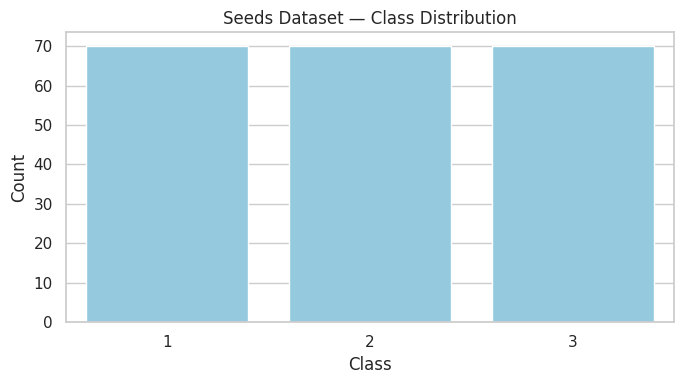

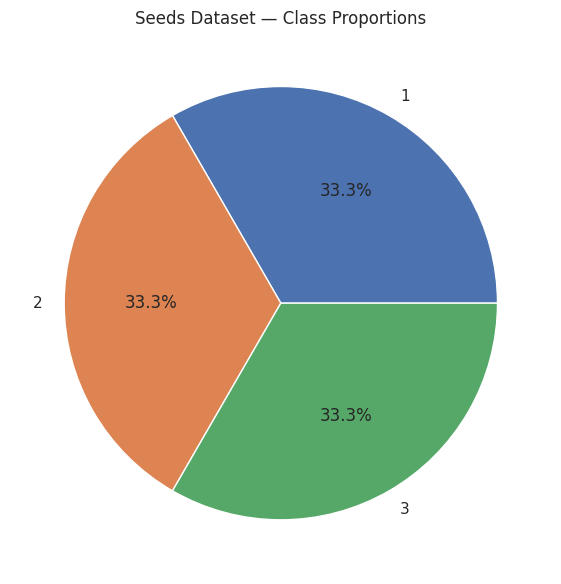

In [11]:
# Bar chart of target classes
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=target_col, color="skyblue")
plt.title("Seeds Dataset — Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Pie chart of target class proportions
df[target_col].value_counts().plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
plt.title("Seeds Dataset — Class Proportions")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Output description — Target distribution (4–6 lines):**  
The bar chart shows the number of samples in each class.  
The pie chart shows the percentage share of each class in the dataset.  
These plots help reveal whether the classes are balanced or imbalanced.  
The class distribution is useful when interpreting the classifier's evaluation metrics.

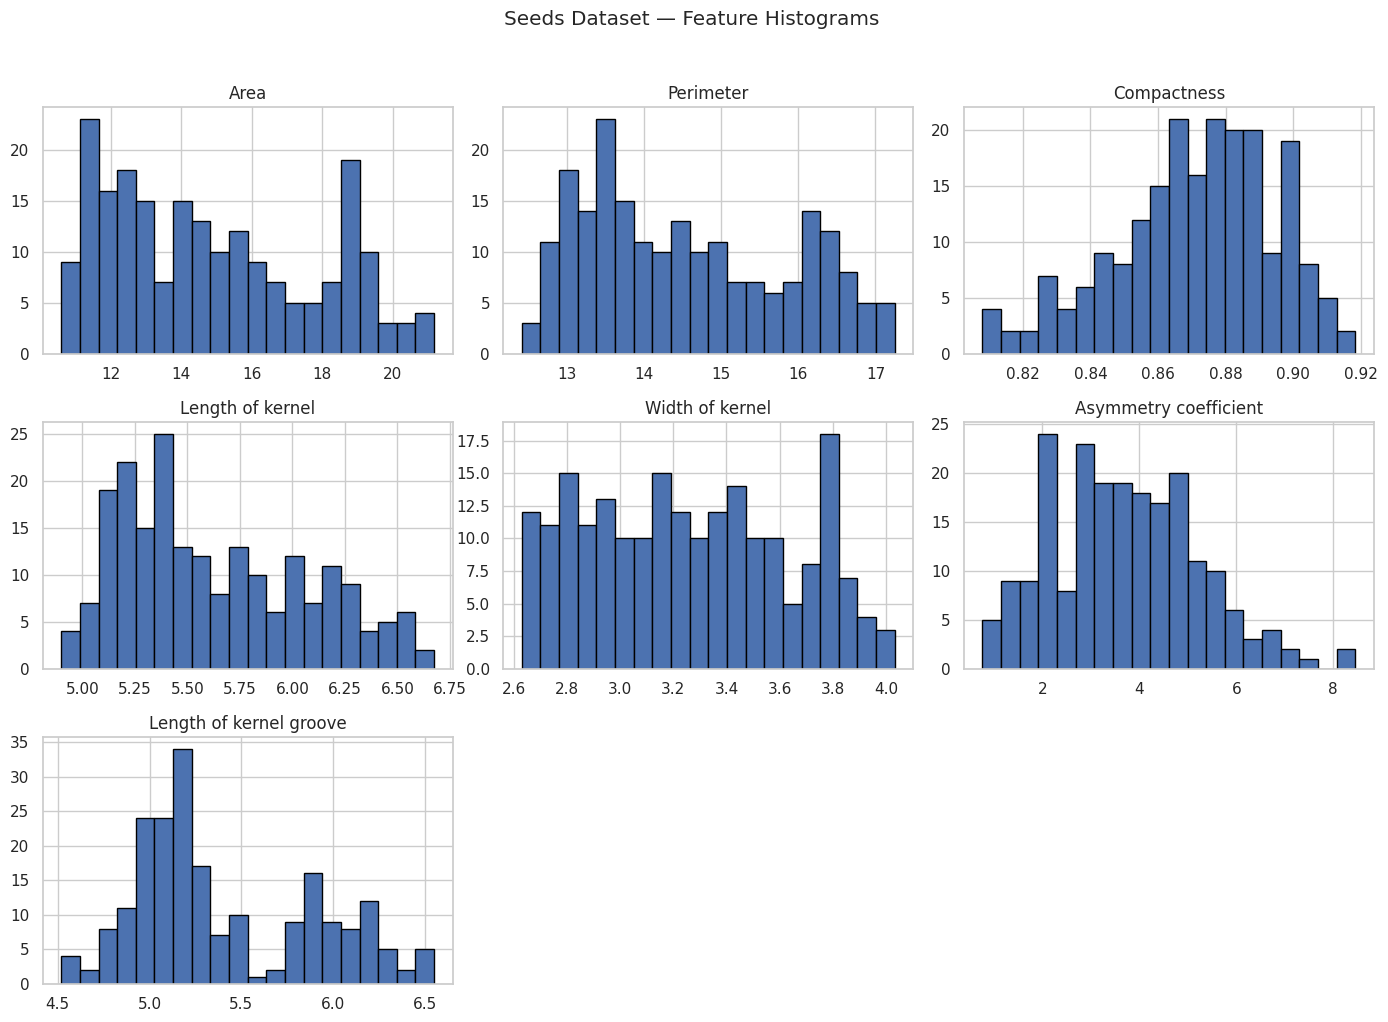

In [12]:
# Histograms for all numeric features
numeric_df = df.select_dtypes(include=np.number)
numeric_features = [c for c in numeric_df.columns if c != target_col]

if numeric_features:
    df[numeric_features].hist(figsize=(14, 10), bins=20, edgecolor="black")
    plt.suptitle("Seeds Dataset — Feature Histograms", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric feature columns available for histograms.")

**Output description — Histograms (4–6 lines):**  
Histograms show how the values of each numerical feature are distributed.  
They can reveal skewness, clusters, and unusually concentrated ranges.  
The plots help compare the scales and shapes of the features.  
These observations support preprocessing decisions before fitting the Perceptron.

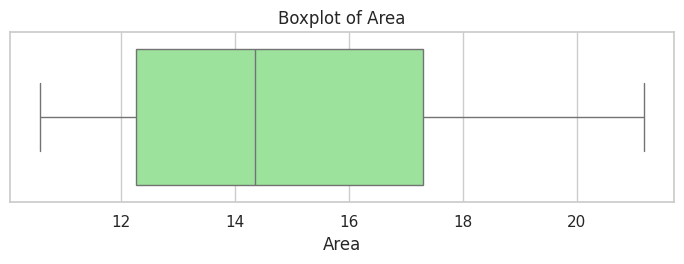

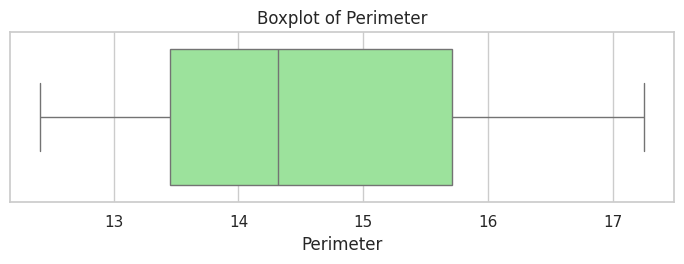

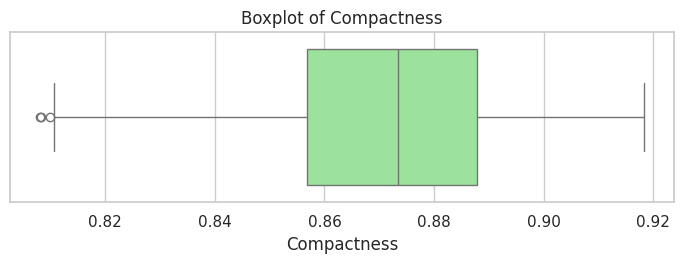

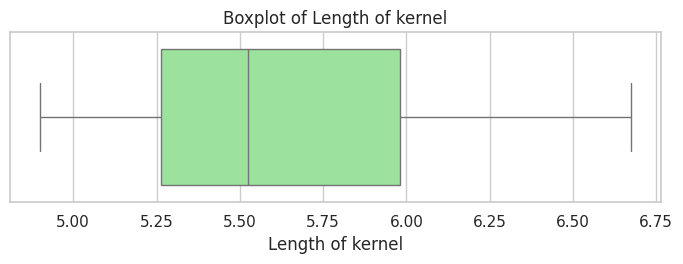

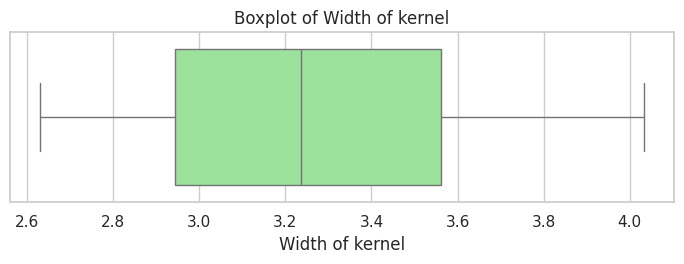

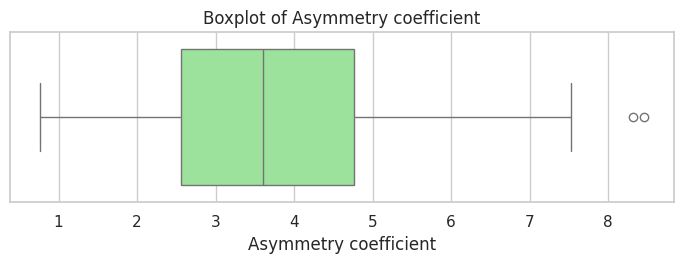

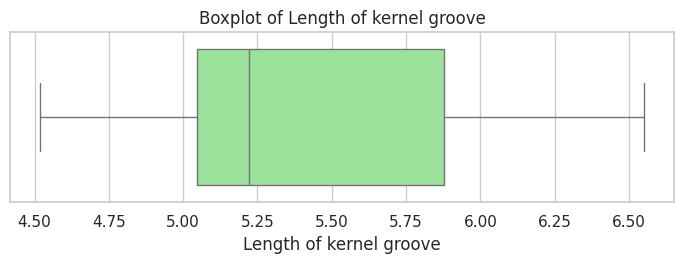

In [13]:
# Boxplots for numeric features to inspect possible outliers
for col in numeric_features:
    plt.figure(figsize=(7, 2.8))
    sns.boxplot(x=df[col], color="lightgreen")
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

**Output description — Boxplots (4–6 lines):**  
Each boxplot summarizes the median, quartiles, and spread of a numerical feature.  
Points beyond the whiskers may indicate potential outliers.  
Outliers are inspected rather than removed automatically.  
This step helps understand feature variability before model training.

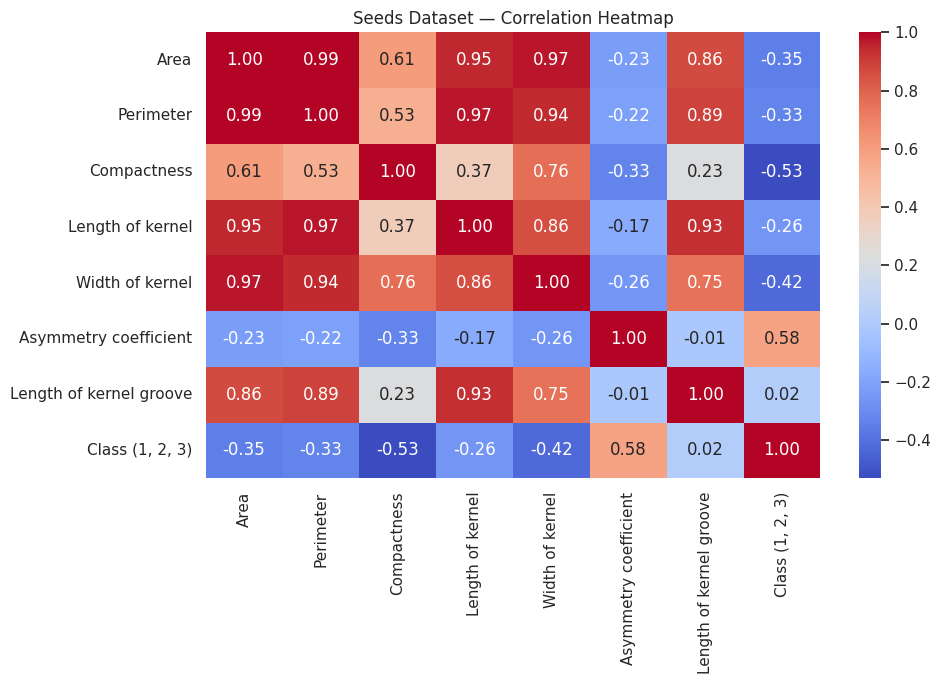

In [14]:
# Correlation heatmap for numeric columns
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Seeds Dataset — Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numeric columns are needed for a correlation heatmap.")

**Output description — Correlation heatmap (4–6 lines):**  
The heatmap displays pairwise correlations among numerical columns.  
Values closer to +1 indicate positive linear association, while values closer to −1 indicate negative association.  
Values near zero suggest weaker linear relationships.  
Correlation does not imply causation, but the heatmap helps summarize feature relationships.

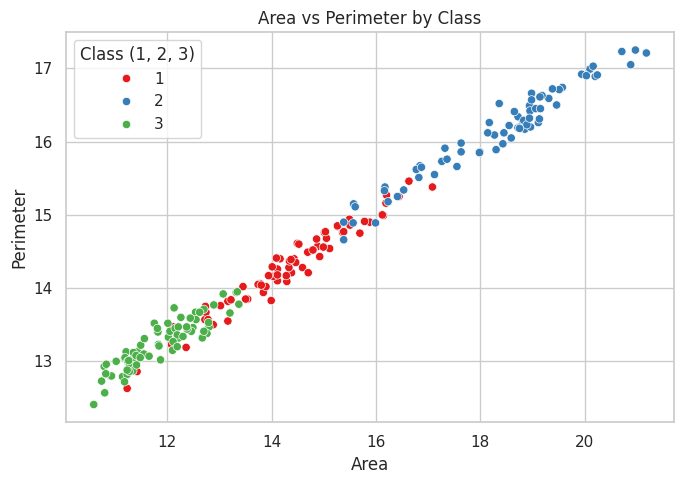

In [15]:
# Scatter plot using the first two numeric features
if len(numeric_features) >= 2:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=numeric_features[0], y=numeric_features[1],
                    hue=target_col, palette="Set1")
    plt.title(f"{numeric_features[0]} vs {numeric_features[1]} by Class")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numeric feature columns are needed for a scatter plot.")

**Output description — Feature scatter plot (4–6 lines):**  
The scatter plot shows the relationship between two numerical features.  
Each point represents one sample, and its color indicates the target class.  
Separate point clusters may indicate that the selected features help distinguish classes.  
Overlap between classes suggests that these two features alone may not fully separate them.

## 4. Prepare Data and Split into Training and Testing Sets

In [16]:
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

# Remove rows with missing target labels, since the model cannot learn from them.
valid_target = y.notna()
X = X.loc[valid_target]
y = y.loc[valid_target]

# Convert target labels to strings for consistent multi-class handling.
y = y.astype(str)

stratify_y = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratify_y
)

print("Target column:", target_col)
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Target column: Class (1, 2, 3)
Training feature shape: (168, 7)
Testing feature shape: (42, 7)
Training target shape: (168,)
Testing target shape: (42,)


**Output description — Train-test split (4–6 lines):**  
The dataset is divided into training and testing subsets.  
The training set is used to learn the model parameters.  
The test set is held out to evaluate predictions on unseen records.  
Stratification is used when class counts allow it, helping preserve class proportions across the split.

## 5. Train the Perceptron Classifier

In [17]:
perceptron_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("perceptron", Perceptron(max_iter=1000, eta0=0.1, random_state=42, tol=1e-3))
])

perceptron_model.fit(X_train, y_train)
y_pred = perceptron_model.predict(X_test)

print("Perceptron training completed.")

Perceptron training completed.


**Output description — Model training (4–6 lines):**  
The pipeline first fills missing feature values using training-set medians.  
It then standardizes the features before passing them to the Perceptron classifier.  
The model learns its classification boundary from the training data.  
Predictions are generated for the held-out test set for evaluation.

## 6. Model Evaluation

In [18]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Weighted Precision:", round(precision, 4))
print("Weighted Recall:", round(recall, 4))
print("Weighted F1-score:", round(f1, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9286
Weighted Precision: 0.9327
Weighted Recall: 0.9286
Weighted F1-score: 0.9284

Classification Report:
              precision    recall  f1-score   support

           1       0.92      0.86      0.89        14
           2       0.88      1.00      0.93        14
           3       1.00      0.93      0.96        14

    accuracy                           0.93        42
   macro avg       0.93      0.93      0.93        42
weighted avg       0.93      0.93      0.93        42



**Output description — Evaluation metrics (4–6 lines):**  
Accuracy measures the fraction of correctly classified test samples.  
Weighted precision and recall summarize performance across classes while accounting for their support.  
The weighted F1-score combines precision and recall into one measure.  
The classification report gives per-class results to help identify differences in performance.

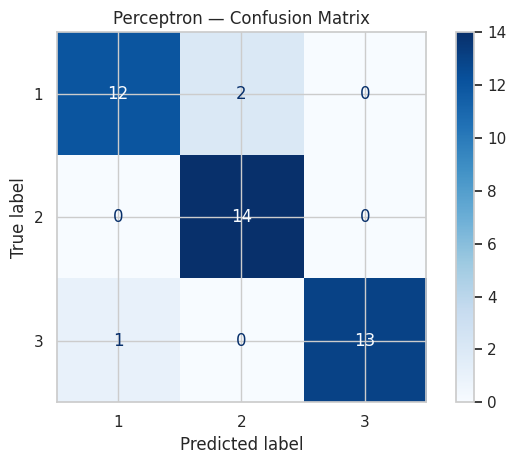

In [19]:
# Confusion matrix
labels = perceptron_model.named_steps["perceptron"].classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d")
plt.title("Perceptron — Confusion Matrix")
plt.tight_layout()
plt.show()

**Output description — Confusion matrix (4–6 lines):**  
The confusion matrix compares the true class labels with the predicted labels.  
Diagonal cells represent correctly classified samples.  
Off-diagonal cells show samples assigned to the wrong class.  
This visualization helps identify which classes the Perceptron confuses most often.

In [20]:
# Display a sample of actual and predicted labels
comparison = pd.DataFrame({
    "Actual Class": y_test.reset_index(drop=True),
    "Predicted Class": pd.Series(y_pred).reset_index(drop=True)
})
display(comparison.head(10))

,Actual Class,Predicted Class
0,1,1
1,3,3
2,2,2
3,3,3
4,2,2
5,3,3
6,2,2
7,1,1
8,2,2
9,2,2


**Output description — Actual vs predicted labels (4–6 lines):**  
This table compares the true labels with the model's predictions for sample test records.  
Matching values indicate correct predictions, while differing values indicate errors.  
It provides a simple record-level view alongside the aggregate metrics.  
Use the confusion matrix and classification report for a fuller evaluation.

## 7. GitHub Repository
**GitHub Repository URL:** `PASTE_YOUR_GITHUB_REPOSITORY_URL_HERE`

**Notebook file:** `Lab_6(ML)_Complete.ipynb`

**Description:** This notebook implements the Perceptron Learning Algorithm on the Seeds dataset, including EDA, preprocessing, training, evaluation, and visualizations.

After uploading this notebook to GitHub, replace the placeholder above with the actual repository URL.

## 8. Viva Questions with Answers

**1. What is the Perceptron Learning Algorithm?**  
It is a supervised learning algorithm that learns a linear decision boundary by updating weights and bias when predictions are incorrect.

**2. What is the role of the learning rate?**  
The learning rate controls the size of each weight and bias update during training.

**3. Why is feature scaling useful for a Perceptron?**  
Scaling brings features to comparable ranges, which can help make optimization more stable when input variables have different magnitudes.

**4. What is a limitation of a single-layer Perceptron?**  
A single-layer Perceptron can only learn linear decision boundaries and cannot solve problems that are not linearly separable without a more suitable strategy or model.

**5. Why should the test set not be used to fit the scaler?**  
Fitting preprocessing on the test set causes data leakage. The scaler should be fitted on training data and then applied unchanged to the test data.

## 9. Conclusion
The Perceptron classifier was implemented using the Seeds dataset. EDA was performed before training to inspect data quality, class balance, feature distributions, potential outliers, and relationships between features. Missing feature values were imputed and numerical features were standardized in a pipeline. Model performance was evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, a classification report, and a confusion matrix.

**Before submission:** Run all cells, verify the actual output values, capture screenshots using a light/white notebook theme, and upload the notebook to GitHub. Replace the GitHub URL placeholder with your repository link.